# STEP 1. 환경 세팅


In [4]:
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = '/content/drive/MyDrive/carbon_scheduler'
DATA_DIR = f'{BASE_DIR}/data'
MODEL_DIR = f'{BASE_DIR}/models'
LOG_DIR   = f'{BASE_DIR}/logs'

import os
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)
print("Drive 마운트 완료")
print(f"BASE_DIR: {BASE_DIR}")

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import joblib
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import holidays
import warnings
warnings.filterwarnings('ignore')
from datetime import datetime
import gc
import json
import time
from copy import deepcopy

Mounted at /content/drive
Drive 마운트 완료
BASE_DIR: /content/drive/MyDrive/carbon_scheduler


In [5]:
# 리전 설정 (Electricity Maps API 존 키)
REGIONS = {
    'KR':          'Korea',
    'US-CAL-CISO': 'US West (California)',
    'US-TEX-ERCO': 'US Central (Texas)',
    'US-NY-NYIS':  'US East (New York)',
    'FR':          'France',
    'DE':          'Germany',
    'IN':       'India West',
    'JP':       'Japan (Tokyo)'
}
# 리전별 공휴일 코드
HOLIDAY_CODES = {
    'KR':          'KR',
    'US-CAL-CISO': 'US',
    'US-TEX-ERCO': 'US',
    'US-NY-NYIS':  'US',
    'FR':          'FR',
    'DE':          'DE',
    'IN':       'IN',
    'JP':       'JP'
}

# 날씨 피처가 있는 리전 (시간별 관측치: 풍속, 일사량, 기온)
# → 나머지 5개 리전은 날씨 데이터가 없어 기존 10개 피처만 사용
# 풍속/일사량은 발전 공급이 몰린 지점(풍력단지/태양광단지), 기온은 수요(냉난방 부하)가 몰린
# 대도시 지점에서 수집 — 서로 다른 기준으로 고른 지점이라 컬럼별로 좌표가 다름
#   US-TEX-ERCO: 풍속=Sweetwater(서텍사스 풍력단지) / 일사량=Fort Stockton(퍼미안 분지 태양광단지) / 기온=DFW(ERCOT 최대 수요지)
#   US-CAL-CISO: 기온=Riverside/Inland Empire(CAISO·SCE 관할, 남캘리포니아 냉방수요 급증 지역)
#   DE:          기온=Frankfurt(독일 중부, 전국 수요 대표 지점)
WEATHER_REGIONS = ['US-TEX-ERCO', 'US-CAL-CISO', 'DE']

# 리전별 날씨 CSV 파일명 (DATA_DIR에 업로드되어 있어야 함)
# 컬럼: timestamp, region, wind_speed_10m, shortwave_radiation, temperature_2m
WEATHER_CSV_FILES = {
    'US-TEX-ERCO': 'weather_US-TEX-ERCO.csv',
    'US-CAL-CISO': 'weather_US-CAL-CISO.csv',
    'DE':          'weather_DE.csv',
}
WEATHER_RAW_COLS     = ['wind_speed_10m', 'shortwave_radiation', 'temperature_2m']
WEATHER_FEATURE_COLS = ['wind_speed_10m_norm', 'shortwave_radiation_norm', 'temperature_2m_norm']

In [6]:
BASE_INPUT_SIZE = 10  # 기본 입력 피처 수 (날씨 피처 미포함)
                      # WEATHER_REGIONS는 WEATHER_FEATURE_COLS(3개)가 추가됨 → get_input_size(region) 참고
HIDDEN_SIZE  = 64    # LSTM hidden state 차원
NUM_LAYERS   = 2     # LSTM 레이어 수
OUTPUT_SIZE  = 24    # 예측 시간 수 (향후 24시간)
SEQ_LEN      = 168   # 입력 시퀀스 길이 (1주일 = 168시간)

BATCH_SIZE   = 64
LEARNING_RATE = 0.001
EPOCHS       = 150   # US-CAL-CISO가 100epoch 한도까지 val_MAE 개선 중이었어서 여유 있게 상향
PATIENCE     = 15    # Early Stopping(soft): val MAE가 PATIENCE번 연속 안 줄면 중단
                      # LR이 실제로 깎일 때마다 patience_counter가 리셋됨 (학습 루프 참고)
                      # → 새 LR에서 개선할 기회를 다시 준다
MIN_EPOCHS_BEFORE_STOP = 20  # 이 epoch 전에는 early stopping을 적용하지 않음
                             # (텍사스처럼 우연한 초반 local minimum에 낚여
                             #  단 2epoch 만에 끝나버리는 것을 방지)
HARD_PATIENCE = 30   # Early Stopping(hard backstop): LR이 몇 번 깎였든 상관없이
                      # best_epoch로부터 이 epoch 이상 지나면 무조건 종료
                      # → scheduler의 plateau 판정 임계값이 너무 민감해서 미세한 노이즈에도
                      # 계속 LR을 깎아버리면, soft patience_counter가 매번 리셋되며
                      # early stop이 영영 안 걸리는 문제 발생 가능 (KR에서 실제 발생:
                      # LR이 epoch 46~121 사이 9번 연속 깎이며 150epoch까지 못 멈춤)

TRAIN_RATIO  = 0.8
VAL_RATIO    = 0.1
TEST_RATIO   = 0.1

In [7]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"{device}")

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

cuda


In [8]:
def free_gpu(tag: str = ""):
    """
  GPU 메모리 해제 + 현재 사용량 출력
    → 리전별 학습 완료 후 호출

    Args:
        tag: 어느 시점인지 표시용 문자열 ex) free_gpu("KR 학습 완료 후")
    """
    gc.collect()

    if not torch.cuda.is_available():
      print(f"[free_gpu][{tag}] CUDA 없음")
      return

    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

    allocated = torch.cuda.memory_allocated() / 1024**2
    reserved  = torch.cuda.memory_reserved()  / 1024**2
    print(f"[free_gpu][{tag}] 사용중={allocated:.1f}MB | 예약됨={reserved:.1f}MB")


free_gpu("초기 상태")

[free_gpu][초기 상태] 사용중=0.0MB | 예약됨=0.0MB


# STEP 2. 데이터 로드 및 시각화

In [9]:
TRAIN_CSV = 'carbon_intensity_train_2021_2023.csv'
VAL_CSV   = 'carbon_intensity_val_2024.csv'
TEST_CSV  = 'carbon_intensity_test_2025.csv'

TRAIN_CSV_PATH = os.path.join(DATA_DIR, TRAIN_CSV)
VAL_CSV_PATH   = os.path.join(DATA_DIR, VAL_CSV)
TEST_CSV_PATH  = os.path.join(DATA_DIR, TEST_CSV)

df_train = pd.read_csv(TRAIN_CSV_PATH)
df_val = pd.read_csv(VAL_CSV_PATH)
df_test = pd.read_csv(TEST_CSV_PATH)

# timestamp 파싱
for _df in [df_train, df_val, df_test]:
    _df['timestamp'] = pd.to_datetime(_df['timestamp'])

df_train = df_train.sort_values(['region', 'timestamp']).reset_index(drop=True)
df_val   = df_val.sort_values(['region', 'timestamp']).reset_index(drop=True)
df_test  = df_test.sort_values(['region', 'timestamp']).reset_index(drop=True)

# 전처리 전 원본 보존
train_raw_path = os.path.join(DATA_DIR, 'raw_train.parquet')
val_raw_path   = os.path.join(DATA_DIR, 'raw_val.parquet')
test_raw_path  = os.path.join(DATA_DIR, 'raw_test.parquet')
df_train.to_parquet(train_raw_path, index=False)
df_val.to_parquet(val_raw_path,     index=False)
df_test.to_parquet(test_raw_path,   index=False)

# 날씨 데이터 로드 (DE, US-TEX-ERCO, US-CAL-CISO만 해당)
# WEATHER_CSV_FILES에 지정된 파일이 DATA_DIR에 업로드되어 있어야 함
weather_frames = []
for region, filename in WEATHER_CSV_FILES.items():
    weather_path = os.path.join(DATA_DIR, filename)
    _wdf = pd.read_csv(weather_path)
    _wdf['timestamp'] = pd.to_datetime(_wdf['timestamp'])
    weather_frames.append(_wdf)

df_weather = pd.concat(weather_frames, ignore_index=True)
df_weather = df_weather.sort_values(['region', 'timestamp']).reset_index(drop=True)
print(f"날씨 데이터 로드: {len(df_weather):,}행 ({', '.join(WEATHER_REGIONS)})")

weather_raw_path = os.path.join(DATA_DIR, 'raw_weather.parquet')
df_weather.to_parquet(weather_raw_path, index=False)

날씨 데이터 로드: 146,016행 (US-TEX-ERCO, US-CAL-CISO, DE)



탄소강도 시계열 시각화 중 (train)...


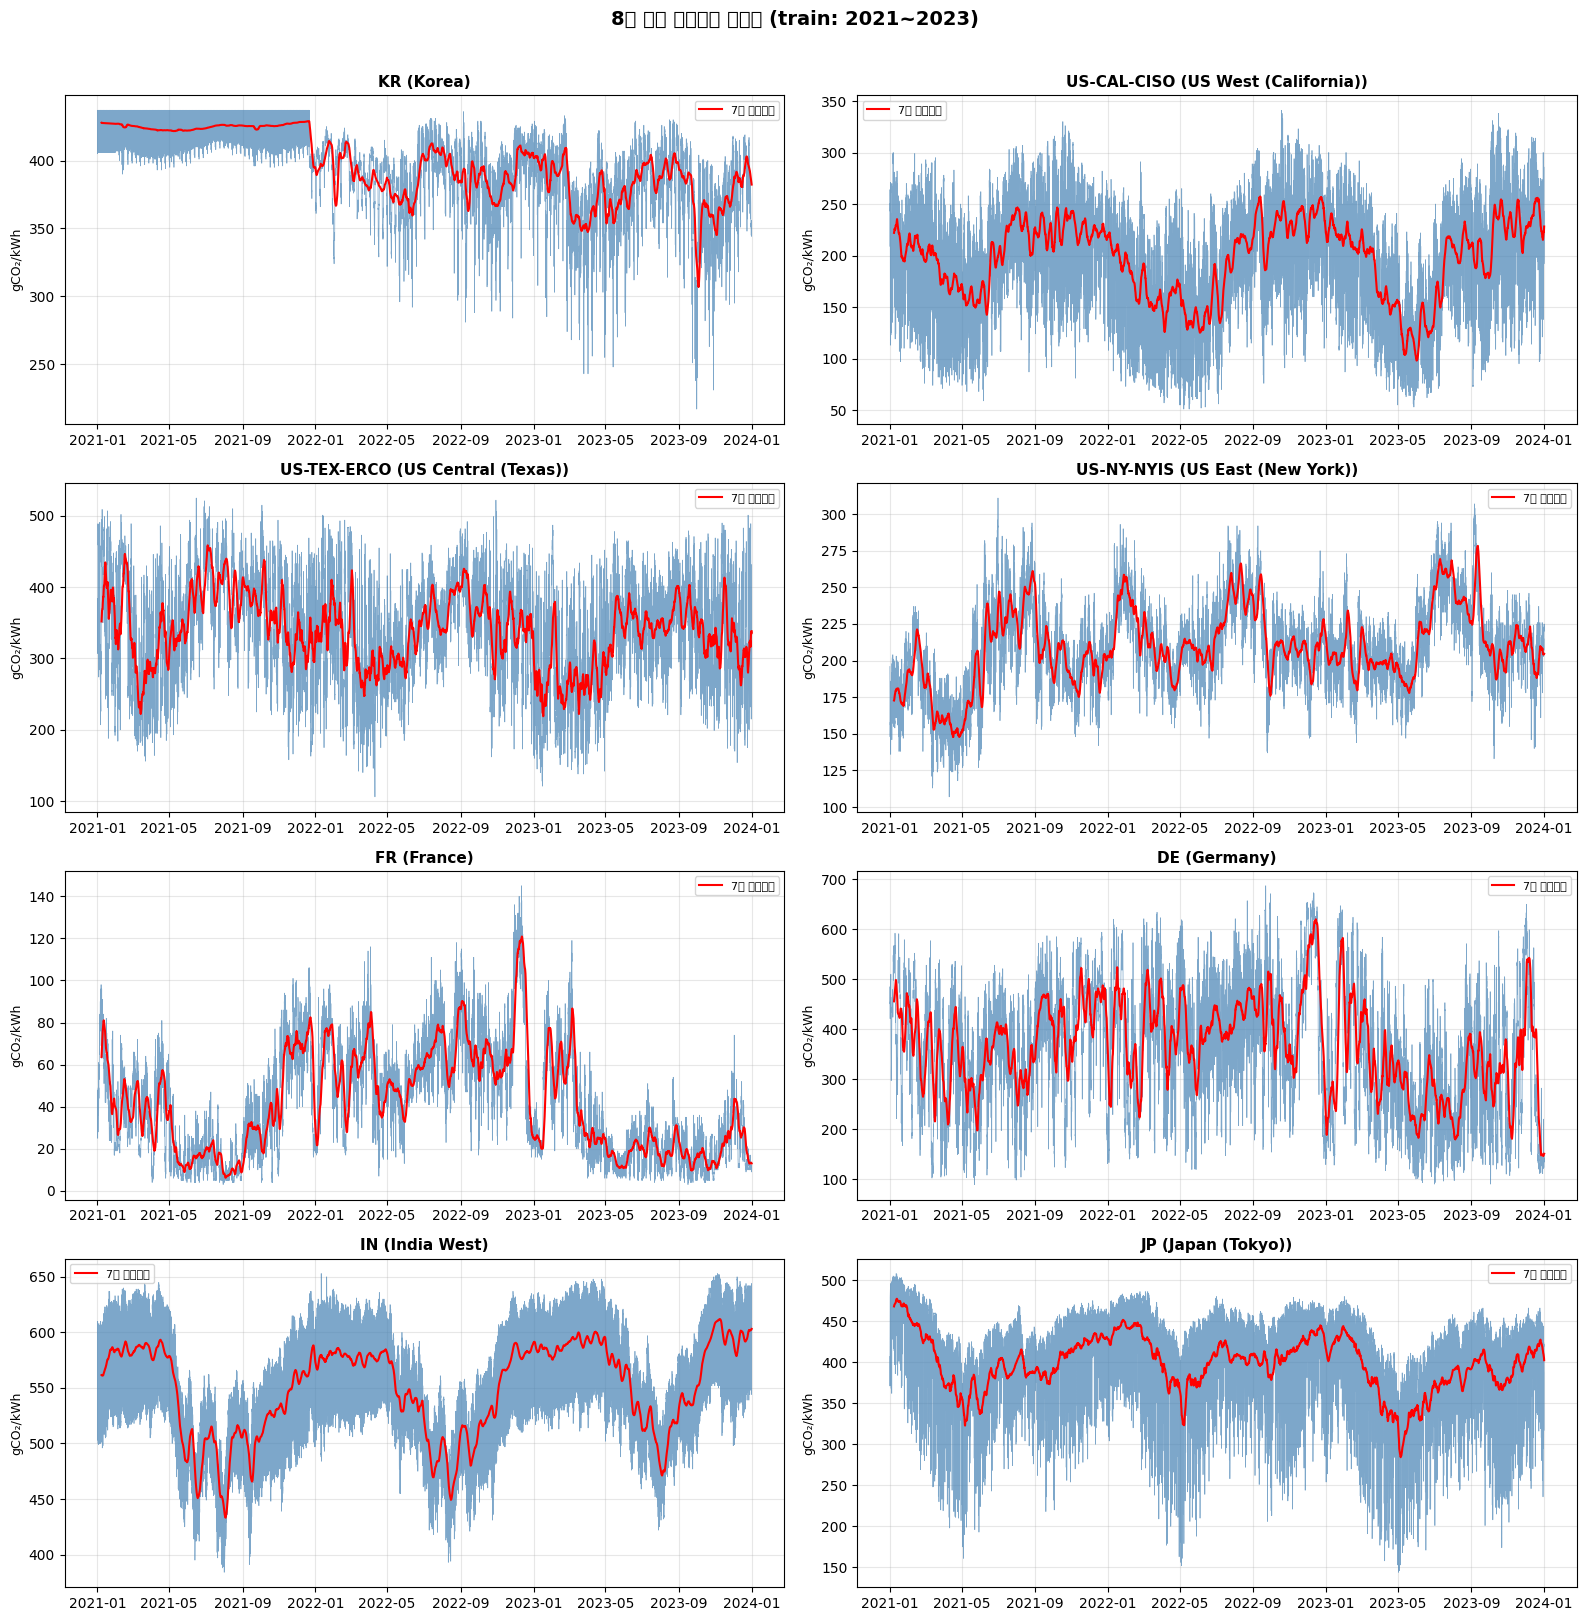

시각화 저장: /content/drive/MyDrive/carbon_scheduler/logs/carbon_intensity_overview.png


In [10]:
# 시각화
print("\n탄소강도 시계열 시각화 중 (train)...")

fig, axes = plt.subplots(4, 2, figsize=(16, 16))
axes = axes.flatten()

for idx, region in enumerate(REGIONS.keys()):
    region_df = df_train[df_train['region'] == region].copy()
    ax = axes[idx]

    ax.plot(region_df['timestamp'], region_df['carbon_intensity'],
            linewidth=0.5, alpha=0.7, color='steelblue')

    region_df['ma7d'] = region_df['carbon_intensity'].rolling(24*7).mean()
    ax.plot(region_df['timestamp'], region_df['ma7d'],
            linewidth=1.5, color='red', label='7일 이동평균')

    ax.set_title(f"{region} ({REGIONS[region]})", fontsize=11, fontweight='bold')
    ax.set_ylabel('gCO₂/kWh', fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle('8개 리전 탄소강도 시계열 (train: 2021~2023)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()

plot_path = os.path.join(LOG_DIR, 'carbon_intensity_overview.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"시각화 저장: {plot_path}")

# STEP 3. 데이터 전처리

In [11]:
train_raw_path    = os.path.join(DATA_DIR, 'raw_train.parquet')
val_raw_path      = os.path.join(DATA_DIR, 'raw_val.parquet')
test_raw_path     = os.path.join(DATA_DIR, 'raw_test.parquet')
weather_raw_path  = os.path.join(DATA_DIR, 'raw_weather.parquet')
df_train   = pd.read_parquet(train_raw_path)
df_val     = pd.read_parquet(val_raw_path)
df_test    = pd.read_parquet(test_raw_path)
df_weather = pd.read_parquet(weather_raw_path)

# 3-1. 피처 엔지니어링
def add_features(df: pd.DataFrame) -> pd.DataFrame:
    df['hour']      = df['timestamp'].dt.hour
    df['dayofweek'] = df['timestamp'].dt.dayofweek
    df['month']     = df['timestamp'].dt.month

    df['sin_hour']  = np.sin(2 * np.pi * df['hour']      / 24)
    df['cos_hour']  = np.cos(2 * np.pi * df['hour']      / 24)
    df['sin_dow']   = np.sin(2 * np.pi * df['dayofweek'] / 7)
    df['cos_dow']   = np.cos(2 * np.pi * df['dayofweek'] / 7)
    df['sin_month'] = np.sin(2 * np.pi * df['month']     / 12)
    df['cos_month'] = np.cos(2 * np.pi * df['month']     / 12)

    df['cfe_pct_norm'] = df['cfe_pct'] / 100.0
    df['re_pct_norm']  = df['re_pct']  / 100.0

    years = list(range(
        df['timestamp'].dt.year.min(),
        df['timestamp'].dt.year.max() + 1
    ))
    holiday_sets = {
        region: set(holidays.country_holidays(HOLIDAY_CODES[region], years=years).keys())
        for region in REGIONS.keys()
    }
    df['is_holiday'] = df.apply(
        lambda row: int(row['timestamp'].date() in holiday_sets[row['region']]),
        axis=1
    )

    # 날씨 피처 병합 (WEATHER_REGIONS만 실측값 존재)
    # 나머지 리전은 모델 입력에 쓰지 않는 컬럼이므로 0으로 채워 둠
    df = df.merge(
        df_weather[['timestamp', 'region'] + WEATHER_RAW_COLS],
        on=['timestamp', 'region'], how='left'
    )
    for col in WEATHER_RAW_COLS:
        df[col] = df[col].fillna(0.0)

    return df

# 3-2. 리전별 분리 저장
def save_by_region(df: pd.DataFrame, suffix: str):
    """
    suffix: 'train' / 'val' / 'test'
    → {region}_{suffix}_processed.parquet
    """
    for region in REGIONS.keys():
        region_df = (df[df['region'] == region]
                     .sort_values('timestamp')
                     .reset_index(drop=True))
        save_path = os.path.join(DATA_DIR, f'{region}_{suffix}_processed.parquet')
        region_df.to_parquet(save_path, index=False)
        print(f"  [{region}] {len(region_df):,}행 → {save_path}")

In [12]:
print("\n" + "="*50)
print("train, val, test 전처리")
print("="*50)

print("\n피처 엔지니어링...")
df_train = add_features(df_train)
df_val = add_features(df_val)
df_test = add_features(df_test)

print("\n리전별 저장:")
save_by_region(df_train, suffix='train')
save_by_region(df_val, suffix='val')
save_by_region(df_test, suffix='test')

BASE_FEATURE_COLS = [
    'carbon_intensity',
    'cfe_pct_norm', 're_pct_norm',
    'sin_hour',  'cos_hour',
    'sin_dow',   'cos_dow',
    'sin_month', 'cos_month',
    'is_holiday'
]

def get_feature_cols(region: str) -> list:
    """리전별 LSTM 입력 피처 목록. WEATHER_REGIONS는 날씨 피처 2개가 추가됨."""
    if region in WEATHER_REGIONS:
        return BASE_FEATURE_COLS + WEATHER_FEATURE_COLS
    return BASE_FEATURE_COLS

def get_input_size(region: str) -> int:
    return len(get_feature_cols(region))


train, val, test 전처리

피처 엔지니어링...

리전별 저장:
  [KR] 26,280행 → /content/drive/MyDrive/carbon_scheduler/data/KR_train_processed.parquet
  [US-CAL-CISO] 26,280행 → /content/drive/MyDrive/carbon_scheduler/data/US-CAL-CISO_train_processed.parquet
  [US-TEX-ERCO] 26,280행 → /content/drive/MyDrive/carbon_scheduler/data/US-TEX-ERCO_train_processed.parquet
  [US-NY-NYIS] 26,280행 → /content/drive/MyDrive/carbon_scheduler/data/US-NY-NYIS_train_processed.parquet
  [FR] 26,280행 → /content/drive/MyDrive/carbon_scheduler/data/FR_train_processed.parquet
  [DE] 26,280행 → /content/drive/MyDrive/carbon_scheduler/data/DE_train_processed.parquet
  [IN] 26,280행 → /content/drive/MyDrive/carbon_scheduler/data/IN_train_processed.parquet
  [JP] 26,280행 → /content/drive/MyDrive/carbon_scheduler/data/JP_train_processed.parquet
  [KR] 8,784행 → /content/drive/MyDrive/carbon_scheduler/data/KR_val_processed.parquet
  [US-CAL-CISO] 8,784행 → /content/drive/MyDrive/carbon_scheduler/data/US-CAL-CISO_val_processed.parquet
  

# STEP 4. 리전별 정규화

In [13]:
scalers = {}          # 리전별 scaler (carbon_intensity)
weather_scalers = {}  # 리전별 scaler (날씨 피처, WEATHER_REGIONS만 존재)
region_datasets = {}  # 리전별 분할 데이터

for region in REGIONS.keys():
    print(f"[{region}]")

    train_path = os.path.join(DATA_DIR, f'{region}_train_processed.parquet')
    val_path   = os.path.join(DATA_DIR, f'{region}_val_processed.parquet')
    test_path  = os.path.join(DATA_DIR, f'{region}_test_processed.parquet')

    train_df = pd.read_parquet(train_path).sort_values('timestamp').reset_index(drop=True)
    val_df   = pd.read_parquet(val_path).sort_values('timestamp').reset_index(drop=True)
    test_df  = pd.read_parquet(test_path).sort_values('timestamp').reset_index(drop=True)

    print(f"  train: {len(train_df):,}행  "
          f"{train_df['timestamp'].min().date()} ~ {train_df['timestamp'].max().date()}")
    print(f"  val:   {len(val_df):,}행  "
          f"{val_df['timestamp'].min().date()} ~ {val_df['timestamp'].max().date()}")
    print(f"  test:  {len(test_df):,}행  "
          f"{test_df['timestamp'].min().date()} ~ {test_df['timestamp'].max().date()}")
    # MinMaxScaler: train 데이터로만 fit
    # val/test는 transform만 적용 (data leakage 방지)
    scaler = MinMaxScaler(feature_range=(0, 1))
    scaler.fit(train_df[['carbon_intensity']])

    # 정규화
    for split_df in [train_df, val_df, test_df]:
        split_df['carbon_intensity_scaled'] = scaler.transform(split_df[['carbon_intensity']])
    # scaler 저장 (.pkl) - 추론 시 예측값 역변환에 필요
    scaler_path = os.path.join(MODEL_DIR, f'{region}_scaler.pkl')
    joblib.dump(scaler, scaler_path)
    print(f"  scaler 저장 → {scaler_path}")

    # 날씨 피처 정규화 (WEATHER_REGIONS만 해당) — train으로만 fit
    if region in WEATHER_REGIONS:
        weather_scaler = MinMaxScaler(feature_range=(0, 1))
        weather_scaler.fit(train_df[WEATHER_RAW_COLS])

        for split_df in [train_df, val_df, test_df]:
            split_df[WEATHER_FEATURE_COLS] = weather_scaler.transform(split_df[WEATHER_RAW_COLS])

        weather_scaler_path = os.path.join(MODEL_DIR, f'{region}_weather_scaler.pkl')
        joblib.dump(weather_scaler, weather_scaler_path)
        weather_scalers[region] = weather_scaler
        print(f"  weather scaler 저장 → {weather_scaler_path}")

    # 분할 데이터 저장
    train_df.to_parquet(os.path.join(DATA_DIR, f'{region}_train.parquet'), index=False)
    val_df.to_parquet(  os.path.join(DATA_DIR, f'{region}_val.parquet'),   index=False)
    test_df.to_parquet( os.path.join(DATA_DIR, f'{region}_test.parquet'),  index=False)

    scalers[region] = scaler
    region_datasets[region] = {
        'train': train_df,
        'val':   val_df,
        'test':  test_df
    }
    print()

[KR]
  train: 26,280행  2021-01-01 ~ 2023-12-31
  val:   8,784행  2024-01-01 ~ 2024-12-31
  test:  8,760행  2025-01-01 ~ 2025-12-31
  scaler 저장 → /content/drive/MyDrive/carbon_scheduler/models/KR_scaler.pkl

[US-CAL-CISO]
  train: 26,280행  2021-01-01 ~ 2023-12-31
  val:   8,784행  2024-01-01 ~ 2024-12-31
  test:  8,760행  2025-01-01 ~ 2025-12-31
  scaler 저장 → /content/drive/MyDrive/carbon_scheduler/models/US-CAL-CISO_scaler.pkl
  weather scaler 저장 → /content/drive/MyDrive/carbon_scheduler/models/US-CAL-CISO_weather_scaler.pkl

[US-TEX-ERCO]
  train: 26,280행  2021-01-01 ~ 2023-12-31
  val:   8,784행  2024-01-01 ~ 2024-12-31
  test:  8,760행  2025-01-01 ~ 2025-12-31
  scaler 저장 → /content/drive/MyDrive/carbon_scheduler/models/US-TEX-ERCO_scaler.pkl
  weather scaler 저장 → /content/drive/MyDrive/carbon_scheduler/models/US-TEX-ERCO_weather_scaler.pkl

[US-NY-NYIS]
  train: 26,280행  2021-01-01 ~ 2023-12-31
  val:   8,784행  2024-01-01 ~ 2024-12-31
  test:  8,760행  2025-01-01 ~ 2025-12-31
  scaler 저장 

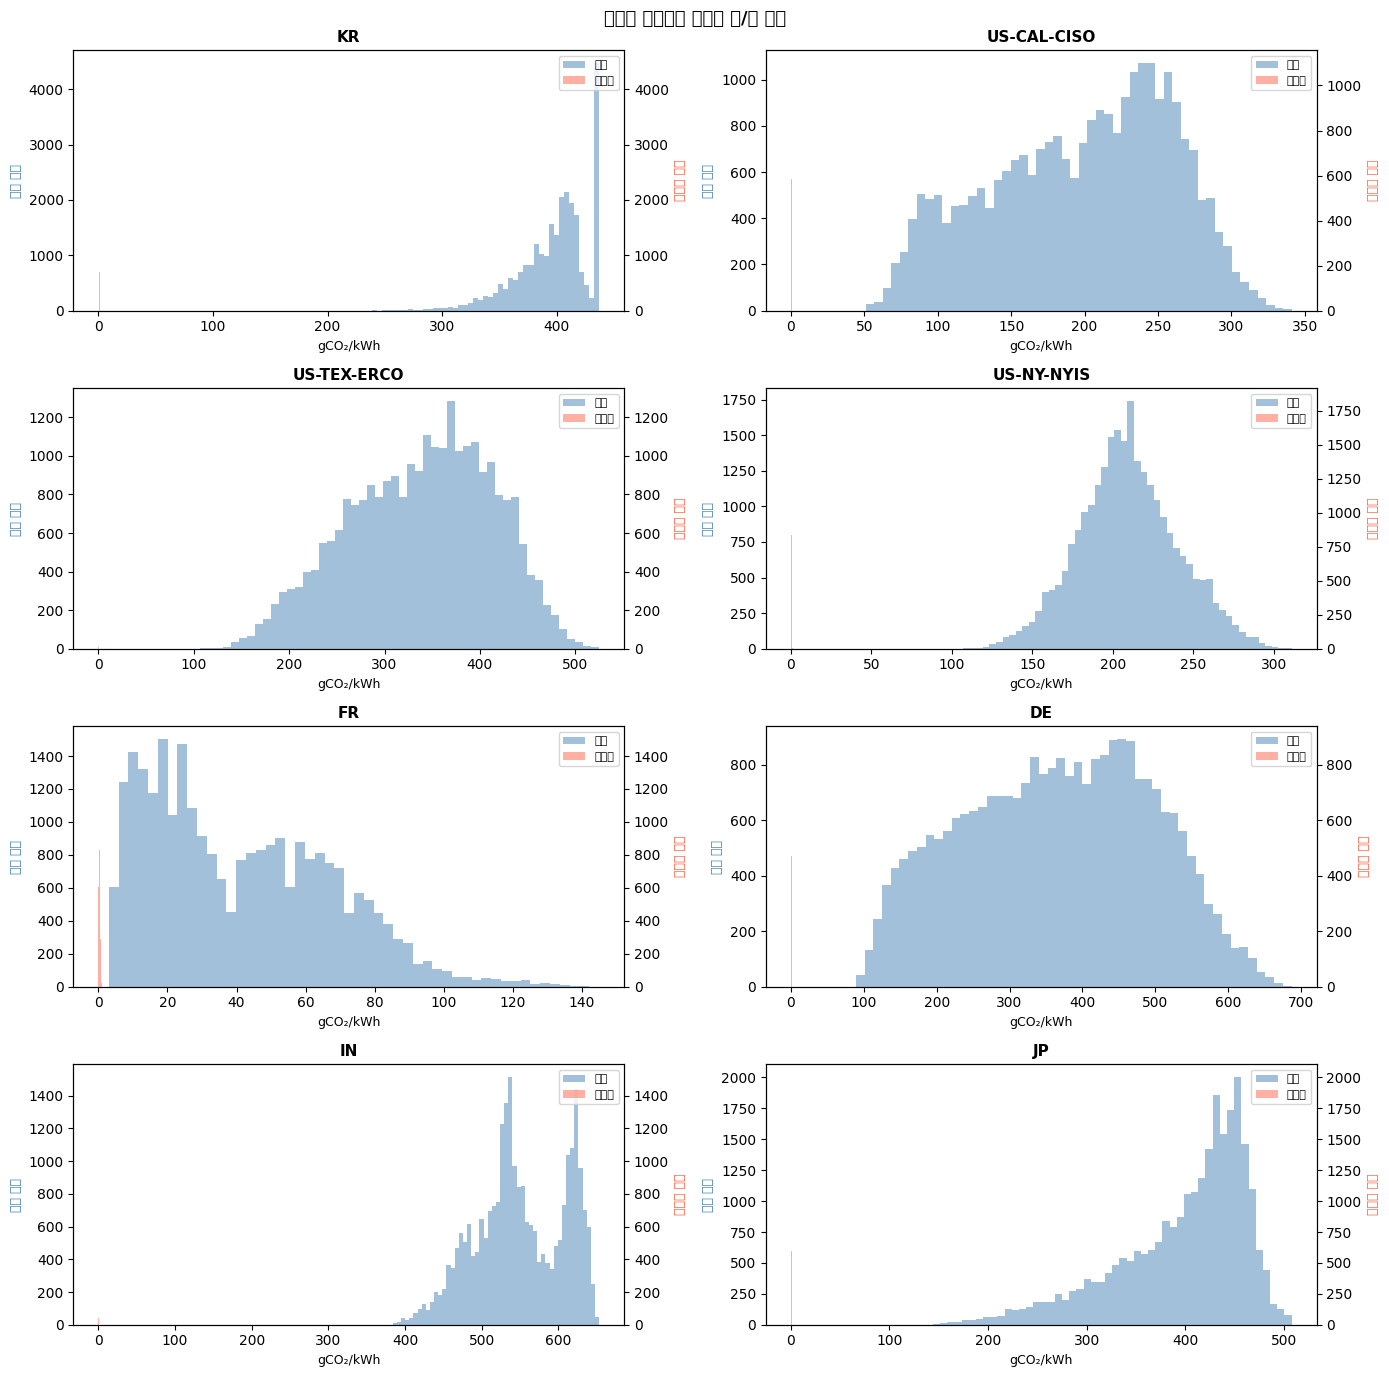

시각화 저장: /content/drive/MyDrive/carbon_scheduler/logs/normalization_distribution.png


In [14]:
# 4-4. 정규화 분포 시각화
fig, axes = plt.subplots(4, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, region in enumerate(REGIONS.keys()):
    train_df = region_datasets[region]['train']
    ax  = axes[idx]
    ax2 = ax.twinx()

    ax.hist(train_df['carbon_intensity'],
            bins=50, alpha=0.5, color='steelblue', label='원본')
    ax2.hist(train_df['carbon_intensity_scaled'],
             bins=50, alpha=0.5, color='tomato', label='정규화')

    ax.set_title(f"{region}", fontsize=11, fontweight='bold')
    ax.set_xlabel('gCO₂/kWh', fontsize=9)
    ax.set_ylabel('원본 빈도', fontsize=9, color='steelblue')
    ax2.set_ylabel('정규화 빈도', fontsize=9, color='tomato')

    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, fontsize=8, loc='upper right')

plt.suptitle('리전별 탄소강도 정규화 전/후 분포', fontsize=13, fontweight='bold')
plt.tight_layout()

plot_path = os.path.join(LOG_DIR, 'normalization_distribution.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"시각화 저장: {plot_path}")

In [15]:
print("\n저장 구조:")
print(f"models/")
for region in REGIONS.keys():
    print(f"  ├── {region}_scaler.pkl")
print(f"data/")
for region in REGIONS.keys():
    print(f"  ├── {region}_train.parquet  (2021~2023)")
    print(f"  ├── {region}_val.parquet    (2024)")
    print(f"  └── {region}_test.parquet   (2025)")


저장 구조:
models/
  ├── KR_scaler.pkl
  ├── US-CAL-CISO_scaler.pkl
  ├── US-TEX-ERCO_scaler.pkl
  ├── US-NY-NYIS_scaler.pkl
  ├── FR_scaler.pkl
  ├── DE_scaler.pkl
  ├── IN_scaler.pkl
  ├── JP_scaler.pkl
data/
  ├── KR_train.parquet  (2021~2023)
  ├── KR_val.parquet    (2024)
  └── KR_test.parquet   (2025)
  ├── US-CAL-CISO_train.parquet  (2021~2023)
  ├── US-CAL-CISO_val.parquet    (2024)
  └── US-CAL-CISO_test.parquet   (2025)
  ├── US-TEX-ERCO_train.parquet  (2021~2023)
  ├── US-TEX-ERCO_val.parquet    (2024)
  └── US-TEX-ERCO_test.parquet   (2025)
  ├── US-NY-NYIS_train.parquet  (2021~2023)
  ├── US-NY-NYIS_val.parquet    (2024)
  └── US-NY-NYIS_test.parquet   (2025)
  ├── FR_train.parquet  (2021~2023)
  ├── FR_val.parquet    (2024)
  └── FR_test.parquet   (2025)
  ├── DE_train.parquet  (2021~2023)
  ├── DE_val.parquet    (2024)
  └── DE_test.parquet   (2025)
  ├── IN_train.parquet  (2021~2023)
  ├── IN_val.parquet    (2024)
  └── IN_test.parquet   (2025)
  ├── JP_train.parquet  (202

# STEP 5. 슬라이딩 윈도우 데이터셋

In [16]:
# 5-1. Dataset 클래스

class CarbonDataset(Dataset):
    """
    슬라이딩 윈도우 방식으로 LSTM 입력/정답 쌍 생성

    슬라이딩 윈도우:
    입력 = [t ~ t+167] (168시간 × N 피처, N=get_input_size(region))
    정답 = [t+168 ~ t+191](향후 24시간 정규화된 탄소강도)
    미래 날씨 = [t+168 ~ t+191] (향후 24시간, WEATHER_REGIONS만 존재)
             → future_weather_cols가 주어지면 CarbonLSTMWithFutureWeather 입력용으로 추가 반환
    """

    def __init__(self, df: pd.DataFrame, feature_cols: list, future_weather_cols: list = None):
        """
        Args:
            df: STEP 4에서 저장한 리전별 분할 데이터
                컬럼: carbon_intensity_scaled, cfe_pct_norm, re_pct_norm, sin_hour, cos_hour,
                      sin_dow, cos_dow, sin_month, cos_month, is_holiday
                      (WEATHER_REGIONS는 wind_speed_10m_norm, shortwave_radiation_norm 추가)
            feature_cols: 리전별 LSTM 입력 피처 목록 (get_feature_cols(region))
            future_weather_cols: 예측 구간(향후 24h)의 날씨 피처 목록. WEATHER_REGIONS만 지정
                                  (예: WEATHER_FEATURE_COLS). None이면 미래 날씨를 반환하지 않음.
        """
        # LSTM 입력 피처 (정규화된 탄소강도 + 시간 피처 [+ 날씨 피처])
        self.features = df[feature_cols].copy()

        # 정답: 정규화된 탄소강도만
        # 역변환해서 실제 gCO₂/kWh로 평가
        self.target = df['carbon_intensity_scaled'].values

        # 정규화된 탄소강도를 피처의 첫 번째 컬럼으로 교체
        self.features['carbon_intensity'] = df['carbon_intensity_scaled'].values
        self.feature_array = self.features.values.astype(np.float32)

        # 예측 구간(향후 24h)의 날씨 — WEATHER_REGIONS만 존재
        self.future_weather_cols = future_weather_cols
        if future_weather_cols is not None:
            self.future_weather_array = df[future_weather_cols].values.astype(np.float32)
        else:
            self.future_weather_array = None

        # 생성 가능한 샘플 수
        self.n_samples = len(df) - SEQ_LEN - OUTPUT_SIZE + 1

    def __len__(self):
        return self.n_samples

    def __getitem__(self, idx):
        # 입력: idx ~ idx+SEQ_LEN (168시간 × N 피처)
        x = self.feature_array[idx : idx + SEQ_LEN]

        # 정답: idx+SEQ_LEN ~ idx+SEQ_LEN+OUTPUT_SIZE (24시간)
        y = self.target[idx + SEQ_LEN : idx + SEQ_LEN + OUTPUT_SIZE]

        if self.future_weather_array is not None:
            # 미래 날씨: idx+SEQ_LEN ~ idx+SEQ_LEN+OUTPUT_SIZE (24시간 × 날씨피처수)
            future_weather = self.future_weather_array[idx + SEQ_LEN : idx + SEQ_LEN + OUTPUT_SIZE]
            return (
                torch.tensor(x, dtype=torch.float32),               # (168, N)
                torch.tensor(future_weather, dtype=torch.float32),  # (24, 날씨피처수)
                torch.tensor(y, dtype=torch.float32)                # (24,)
            )

        return (
            torch.tensor(x, dtype=torch.float32),  # (168, N)
            torch.tensor(y, dtype=torch.float32)   # (24,)
        )


# 5-2. 피처 컬럼
# STEP 3에서 정의한 get_feature_cols(region) 사용
# carbon_intensity → carbon_intensity_scaled로 대체 (Dataset 내부에서 처리)
# WEATHER_REGIONS(US-TEX-ERCO, US-CAL-CISO, DE)는 날씨 피처 2개가 추가되어 입력 크기가 다름
# → 이 리전들은 예측 구간(향후 24h)의 날씨도 CarbonDataset에 별도로 실어서
#   CarbonLSTMWithFutureWeather가 last_hidden과 concat할 수 있게 함


# 5-3. 데이터셋 생성 및 검증
region_loaders = {}  # 리전별 DataLoader 저장

for region in REGIONS.keys():
    print(f"[{region}] (입력 피처 {get_input_size(region)}개)")

    # STEP 4에서 저장한 분할 데이터 로드
    train_df = pd.read_parquet(os.path.join(DATA_DIR, f'{region}_train.parquet'))
    val_df   = pd.read_parquet(os.path.join(DATA_DIR, f'{region}_val.parquet'))
    test_df  = pd.read_parquet(os.path.join(DATA_DIR, f'{region}_test.parquet'))

    feature_cols = get_feature_cols(region)
    use_future_weather = region in WEATHER_REGIONS
    future_weather_cols = WEATHER_FEATURE_COLS if use_future_weather else None

    # Dataset 생성
    train_dataset = CarbonDataset(train_df, feature_cols, future_weather_cols)
    val_dataset   = CarbonDataset(val_df, feature_cols, future_weather_cols)
    test_dataset  = CarbonDataset(test_df, feature_cols, future_weather_cols)

    print(f"  train 샘플 수: {len(train_dataset):,}")
    print(f"  val   샘플 수: {len(val_dataset):,}")
    print(f"  test  샘플 수: {len(test_dataset):,}")

    # DataLoader 생성
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,   # 시계열 순서 유지
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

    region_loaders[region] = {
        'train': train_loader,
        'val':   val_loader,
        'test':  test_loader,
        'train_dataset': train_dataset,
        'val_dataset':   val_dataset,
        'test_dataset':  test_dataset,
        'use_future_weather': use_future_weather,
    }

[KR] (입력 피처 10개)
  train 샘플 수: 26,089
  val   샘플 수: 8,593
  test  샘플 수: 8,569
[US-CAL-CISO] (입력 피처 13개)
  train 샘플 수: 26,089
  val   샘플 수: 8,593
  test  샘플 수: 8,569
[US-TEX-ERCO] (입력 피처 13개)
  train 샘플 수: 26,089
  val   샘플 수: 8,593
  test  샘플 수: 8,569
[US-NY-NYIS] (입력 피처 10개)
  train 샘플 수: 26,089
  val   샘플 수: 8,593
  test  샘플 수: 8,569
[FR] (입력 피처 10개)
  train 샘플 수: 26,089
  val   샘플 수: 8,593
  test  샘플 수: 8,569
[DE] (입력 피처 13개)
  train 샘플 수: 26,089
  val   샘플 수: 8,593
  test  샘플 수: 8,569
[IN] (입력 피처 10개)
  train 샘플 수: 26,089
  val   샘플 수: 8,593
  test  샘플 수: 8,569
[JP] (입력 피처 10개)
  train 샘플 수: 26,089
  val   샘플 수: 8,593
  test  샘플 수: 8,569


# STEP 6. LSTM 모델 정의



In [17]:
# 6-1. CarbonLSTM 모델 정의

class CarbonLSTM(nn.Module):
    """
    탄소강도 24시간 예측 LSTM 모델

    구조:
        입력 (batch, 168, N)  # N = 리전별 입력 피처 수 (기본 10, 날씨 리전은 12)
            ↓
        LSTM Layer 1 (hidden_size=64)
            ↓
        LSTM Layer 2 (hidden_size=64)
            ↓
        마지막 스텝 hidden state (batch, 64)
            ↓
        Linear (64 → 24)
            ↓
        출력 (batch, 24)  ← 향후 24시간 탄소강도 예측 (정규화된 값)
    """

    def __init__(
        self,
        input_size:  int = BASE_INPUT_SIZE,  # 리전별 실제값은 get_input_size(region) 사용
        hidden_size: int = HIDDEN_SIZE,  # 64
        num_layers:  int = NUM_LAYERS,   # 2
        output_size: int = OUTPUT_SIZE,  # 24
        dropout:     float = 0.2
    ):
        super().__init__()

        self.hidden_size = hidden_size
        self.num_layers  = num_layers
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )
        self.fc = nn.Linear(hidden_size, output_size)
        self._init_weights()

    def _init_weights(self):
        """
        Xavier 초기화로 학습 초반 gradient 흐름 안정화
        LSTM 게이트 가중치에 적용
        """
        for name, param in self.lstm.named_parameters():
            if 'weight_ih' in name:
                nn.init.xavier_uniform_(param.data)
            elif 'weight_hh' in name:
                nn.init.orthogonal_(param.data)
            elif 'bias' in name:
                param.data.fill_(0)
                # forget gate bias를 1로 초기화 → 학습 초반에 이전 정보를 더 잘 유지
                n = param.size(0)
                param.data[n//4 : n//2].fill_(1.0)

        nn.init.xavier_uniform_(self.fc.weight)
        nn.init.zeros_(self.fc.bias)

    def forward(self, x):
        """
        Args:
            x: (batch, seq_len, input_size)  # input_size는 리전별로 다름 (기본 10, 날씨 리전은 12)

        Returns:
            out: (batch, output_size) = (batch, 24)
        """
        # h0, c0: 초기 hidden state, cell state
        # 매 배치마다 0으로 초기화
        batch_size = x.size(0)
        h0 = torch.zeros(self.num_layers, batch_size, self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, batch_size, self.hidden_size).to(x.device)

        # LSTM forward
        # lstm_out: (batch, seq_len, hidden_size) = (batch, 168, 64)
        #           168 스텝 전부의 hidden state
        # hidden:   마지막 스텝의 hidden state (num_layers, batch, hidden_size)
        lstm_out, (hidden, cell) = self.lstm(x, (h0, c0))

        # 마지막 스텝 hidden state만 사용
        # 168시간 전체를 읽은 후의 최종 압축 상태
        last_hidden = lstm_out[:, -1, :]  # (batch, 24)
        out = self.fc(last_hidden)

        return out


# 6-2. 미래 날씨 결합 CarbonLSTM (WEATHER_REGIONS 전용)

class CarbonLSTMWithFutureWeather(CarbonLSTM):
    """
    CarbonLSTM과 인코더(LSTM)는 동일하지만, 출력층 직전에 예측 구간(향후 24h)의
    날씨를 last_hidden과 concat해서 반영함 — WEATHER_REGIONS(US-CAL-CISO, US-TEX-ERCO, DE) 전용.
    나머지 리전은 미래 날씨가 없으므로 기존 CarbonLSTM을 그대로 사용.

    구조:
        과거 168h → LSTM → last_hidden (hidden_size)
        미래 24h 날씨 (OUTPUT_SIZE × 날씨피처수) → flatten
        concat(last_hidden, 미래 날씨) → Linear(hidden_size + future_weather_dim → output_size)
    """

    def __init__(
        self,
        input_size:  int,
        hidden_size: int = HIDDEN_SIZE,
        num_layers:  int = NUM_LAYERS,
        output_size: int = OUTPUT_SIZE,
        future_weather_dim: int = OUTPUT_SIZE * len(WEATHER_FEATURE_COLS),
        dropout:     float = 0.2
    ):
        super().__init__(input_size, hidden_size, num_layers, output_size, dropout)
        # last_hidden(hidden_size) + 미래 날씨(future_weather_dim) → output_size로 출력층 재정의
        self.fc = nn.Linear(hidden_size + future_weather_dim, output_size)
        nn.init.xavier_uniform_(self.fc.weight)
        nn.init.zeros_(self.fc.bias)

    def forward(self, x, future_weather):
        """
        Args:
            x: (batch, SEQ_LEN, input_size) — 과거 168h
            future_weather: (batch, OUTPUT_SIZE, 날씨피처수) — 예측 구간(향후 24h) 날씨 (정규화됨)

        Returns:
            out: (batch, output_size)
        """
        batch_size = x.size(0)
        h0 = torch.zeros(self.num_layers, batch_size, self.hidden_size).to(x.device)
        c0 = torch.zeros(self.num_layers, batch_size, self.hidden_size).to(x.device)

        lstm_out, _ = self.lstm(x, (h0, c0))
        last_hidden = lstm_out[:, -1, :]                       # (batch, hidden_size)

        future_flat = future_weather.reshape(batch_size, -1)   # (batch, future_weather_dim)
        out = self.fc(torch.cat([last_hidden, future_flat], dim=1))

        return out

# STEP 7. Trainig

In [18]:
# 7-1. 단일 epoch 학습 / 검증 함수

def train_one_epoch(model, loader, criterion, optimizer, device, use_future_weather=False):
    model.train()
    total_loss = 0.0

    for batch in loader:
        if use_future_weather:
            x, future_weather, y = batch
            x, future_weather, y = x.to(device), future_weather.to(device), y.to(device)
            optimizer.zero_grad()
            pred = model(x, future_weather)
        else:
            x, y = batch
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            pred = model(x)

        loss = criterion(pred, y)
        loss.backward()

        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()
        total_loss += loss.item()

    return total_loss / len(loader)


def validate(model, loader, criterion, device, use_future_weather=False):
    """MSE, 정규화된 값 기준 검증 — Early Stopping 판단용"""
    model.eval()
    total_loss = 0.0

    with torch.no_grad():
        for batch in loader:
            if use_future_weather:
                x, future_weather, y = batch
                x, future_weather, y = x.to(device), future_weather.to(device), y.to(device)
                pred = model(x, future_weather)
            else:
                x, y = batch
                x, y = x.to(device), y.to(device)
                pred = model(x)
            loss = criterion(pred, y)
            total_loss += loss.item()

    return total_loss / len(loader)

def validate_mae(model, loader, scaler, device, use_future_weather=False):
    """
    MAE, 역변환된 실제 gCO₂/kWh 기준 검증 — best model 선택용

    MSE는 큰 오차 하나에 과민 반응할 수 있어서
    "정규화 loss는 낮은데 실제 단위로는 안 좋은" 모델이 뽑힐 위험이 있음
    → 우리 목표(MAE<20)와 직접 일치하는 MAE로 best epoch 판단
    """
    model.eval()
    all_preds   = []
    all_targets = []

    with torch.no_grad():
        for batch in loader:
            if use_future_weather:
                x, future_weather, y = batch
                x, future_weather = x.to(device), future_weather.to(device)
                pred = model(x, future_weather)
            else:
                x, y = batch
                x = x.to(device)
                pred = model(x)
            all_preds.append(pred.cpu().numpy())
            all_targets.append(y.numpy())

    all_preds   = np.concatenate(all_preds,   axis=0)
    all_targets = np.concatenate(all_targets, axis=0)

    # 역변환
    pred_inv = scaler.inverse_transform(
        all_preds.reshape(-1, 1)
    ).reshape(all_preds.shape)
    target_inv = scaler.inverse_transform(
        all_targets.reshape(-1, 1)
    ).reshape(all_targets.shape)

    mae = np.mean(np.abs(target_inv - pred_inv))
    return float(mae)

# 7-2. 리전별 학습 함수


def train_region(region: str) -> dict:
    """
    단일 리전 LSTM 모델 학습
    Args:
        region: 리전 키 (ex. 'KR', 'FR')
    Returns:
        학습 결과 딕셔너리 (loss 기록, 최적 epoch 등)
    """
    print(f"\n{'='*50}")
    print(f"[{region}] {REGIONS[region]} 학습 시작")
    print(f"{'='*50}")

    torch.manual_seed(SEED)
    np.random.seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    train_loader = region_loaders[region]['train']
    val_loader   = region_loaders[region]['val']
    use_future_weather = region_loaders[region]['use_future_weather']

    # val MAE 계산에 필요한 scaler
    scaler = joblib.load(os.path.join(MODEL_DIR, f'{region}_scaler.pkl'))

    # 리전별 입력 피처 수 (WEATHER_REGIONS는 날씨 피처 2개 추가)
    input_size = get_input_size(region)

    if use_future_weather:
        # 예측 구간(향후 24h) 날씨를 last_hidden과 concat하는 모델 (WEATHER_REGIONS 전용)
        model = CarbonLSTMWithFutureWeather(
            input_size=input_size,
            hidden_size=HIDDEN_SIZE,
            num_layers=NUM_LAYERS,
            output_size=OUTPUT_SIZE,
            future_weather_dim=OUTPUT_SIZE * len(WEATHER_FEATURE_COLS),
            dropout=0.2
        ).to(device)
    else:
        model = CarbonLSTM(
            input_size=input_size,
            hidden_size=HIDDEN_SIZE,
            num_layers=NUM_LAYERS,
            output_size=OUTPUT_SIZE,
            dropout=0.2
        ).to(device)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=1e-4
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=8
        # DE가 patience=5일 때 30epoch 안에 LR이 4번 깎여 초기 수렴 후 조기종료됐던 문제 완화
    )

    # 학습 기록
    train_losses = []
    val_losses   = []      # MSE (Early Stopping 판단)
    val_maes     = []      # MAE (best model 선택)

    best_val_mae     = float('inf')
    best_model_state = None
    best_epoch       = 0
    patience_counter = 0
    start_time = time.time()

    for epoch in range(1, EPOCHS + 1):

        train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device, use_future_weather)
        val_loss   = validate(model, val_loader, criterion, device, use_future_weather)
        val_mae    = validate_mae(model, val_loader, scaler, device, use_future_weather)

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        val_maes.append(val_mae)

        lr_before_step = optimizer.param_groups[0]['lr']
        scheduler.step(val_loss)
        lr_after_step = optimizer.param_groups[0]['lr']

        if val_mae < best_val_mae:
            best_val_mae      = val_mae
            best_model_state  = deepcopy(model.state_dict())
            best_epoch         = epoch
            patience_counter  = 0
        else:
            patience_counter += 1

        # LR이 실제로 깎였으면 patience_counter 리셋 (soft)
        # → early stopping(MAE 기준)과 scheduler(MSE 기준)는 서로 다른 지표를 독립적으로
        #   추적하기 때문에, "PATIENCE 숫자가 scheduler patience보다 크다"는 것만으로는
        #   LR이 한 번도 안 깎인 채 early stop이 먼저 발동하는 경주(race) 문제를 못 막음
        #   (CA/TX에서 실제 발생했던 버그). LR이 깎인 직후엔 새 LR에서 개선할 여지를
        #   다시 PATIENCE epoch만큼 지켜본다.
        if lr_after_step < lr_before_step:
            patience_counter = 0
            print(f"  [LR 감소] {lr_before_step:.6f} → {lr_after_step:.6f} "
                  f"(epoch {epoch}) — patience_counter 리셋, 새 LR로 재관찰")

        if epoch % 10 == 0 or epoch == 1:
            elapsed = time.time() - start_time
            current_lr = optimizer.param_groups[0]['lr']
            print(f"  Epoch {epoch:3d}/{EPOCHS} | "
                  f"train_loss={train_loss:.4f} | "
                  f"val_loss(MSE)={val_loss:.4f} | "
                  f"val_MAE={val_mae:.2f} | "
                  f"lr={current_lr:.6f} | "
                  f"경과={elapsed:.0f}s")

        # Early Stopping
        # - soft: MIN_EPOCHS_BEFORE_STOP 이후, patience_counter(LR 감소 시 리셋됨) >= PATIENCE
        # - hard backstop: LR이 몇 번을 깎이며 soft patience_counter를 계속 리셋시키든
        #   상관없이, best_epoch로부터 HARD_PATIENCE epoch가 지나면 무조건 종료
        #   (scheduler가 미세한 노이즈에도 계속 LR을 깎아버려 soft patience가
        #   영영 안 채워지는 문제 방지 — KR에서 실제 발생)
        epochs_since_best = epoch - best_epoch
        should_stop_soft = patience_counter >= PATIENCE
        should_stop_hard = epochs_since_best >= HARD_PATIENCE
        if epoch >= MIN_EPOCHS_BEFORE_STOP and (should_stop_soft or should_stop_hard):
            reason = "hard backstop" if should_stop_hard and not should_stop_soft else "patience"
            print(f"\n  Early Stopping @ epoch {epoch} ({reason}) "
                  f"(best: epoch {best_epoch}, val_MAE={best_val_mae:.2f})")
            break

    model.load_state_dict(best_model_state)
    model_path = os.path.join(MODEL_DIR, f'{region}_lstm.pt')
    torch.save(best_model_state, model_path)
    print(f"\n  모델 저장 → {model_path}")

    training_time = time.time() - start_time
    print(f"  학습 시간: {training_time:.1f}초 ({training_time/60:.1f}분)")
    print(f"  최적 epoch: {best_epoch} | best val_MAE: {best_val_mae:.2f} gCO₂/kWh")

    return {
        'region':        region,
        'best_epoch':    best_epoch,
        'best_val_mae':  best_val_mae,
        'train_losses':  train_losses,
        'val_losses':    val_losses,
        'val_maes':      val_maes,
        'training_time': training_time,
        'model':         model
    }


# 7-3. 8개 리전 순차 학습

print("8개 리전 순차 학습 시작")
all_results = {}

for region in REGIONS.keys():
    result = train_region(region)
    all_results[region] = result
    free_gpu(f"{region} 학습 완료")


# 7-4. 학습 결과 요약

print("\n" + "="*50)
print("전체 학습 결과 요약")
print("="*50)
print(f"{'리전':<15} {'best_epoch':>10} {'best_val_MAE':>13} {'학습시간(분)':>12}")
print("-"*55)

summary = {}
for region, result in all_results.items():
    print(f"{region:<15} "
          f"{result['best_epoch']:>10} "
          f"{result['best_val_mae']:>13.2f} "
          f"{result['training_time']/60:>12.1f}")
    summary[region] = {
        'best_epoch':    result['best_epoch'],
        'best_val_mae':  result['best_val_mae'],
        'training_time': result['training_time']
    }

summary_path = os.path.join(LOG_DIR, 'training_summary.json')
with open(summary_path, 'w') as f:
    json.dump(summary, f, indent=2)
print(f"\n학습 요약 저장 → {summary_path}")

8개 리전 순차 학습 시작

[KR] Korea 학습 시작
  Epoch   1/150 | train_loss=0.0247 | val_loss(MSE)=0.0593 | val_MAE=42.94 | lr=0.001000 | 경과=6s
  Epoch  10/150 | train_loss=0.0069 | val_loss(MSE)=0.0503 | val_MAE=39.43 | lr=0.001000 | 경과=40s
  Epoch  20/150 | train_loss=0.0057 | val_loss(MSE)=0.0334 | val_MAE=31.80 | lr=0.001000 | 경과=79s
  Epoch  30/150 | train_loss=0.0045 | val_loss(MSE)=0.0151 | val_MAE=20.77 | lr=0.001000 | 경과=117s
  Epoch  40/150 | train_loss=0.0038 | val_loss(MSE)=0.0121 | val_MAE=18.06 | lr=0.001000 | 경과=155s
  [LR 감소] 0.001000 → 0.000500 (epoch 46) — patience_counter 리셋, 새 LR로 재관찰
  Epoch  50/150 | train_loss=0.0034 | val_loss(MSE)=0.0089 | val_MAE=15.25 | lr=0.000500 | 경과=194s
  [LR 감소] 0.000500 → 0.000250 (epoch 58) — patience_counter 리셋, 새 LR로 재관찰
  Epoch  60/150 | train_loss=0.0033 | val_loss(MSE)=0.0092 | val_MAE=15.30 | lr=0.000250 | 경과=232s
  [LR 감소] 0.000250 → 0.000125 (epoch 67) — patience_counter 리셋, 새 LR로 재관찰
  Epoch  70/150 | train_loss=0.0032 | val_loss(MSE)=0.00

# STEP 8. Rolling Forecast Evaluation

   - t 시점: 과거 168h 실제값 입력 → t+1~t+24 예측
   - t+1 시점: t+1까지의 실제값 입력 → 다음 예측
   → 예측 후 관측된 실제값이 다음 입력에 자동 반영

출력:
  1) 예측 레코드 (timestamp, horizon, y_true, y_pred, abs_err)
  2) Overall MAE / RMSE / MAPE 요약


In [19]:
# 8-1. 지표 계산 함수

def calc_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    """
    MAE / RMSE / MAPE 계산

    MAPE: 리전별 스케일 차이를 고려한 상대 오차
          FR(평균 20)과 IN(평균 566)을 공정하게 비교 가능
    """
    mae  = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mape = np.mean(np.abs((y_true - y_pred) / np.clip(y_true, 1e-3, None))) * 100
    return {'mae': float(mae), 'rmse': float(rmse), 'mape': float(mape)}


def get_season(month: int) -> str:
    if month in [3, 4, 5]:   return 'Spring'
    if month in [6, 7, 8]:   return 'Summer'
    if month in [9, 10, 11]: return 'Fall'
    return 'Winter'


# 8-2. 리전별 rolling-forecast evaluation

def rolling_forecast_eval(region: str, model) -> pd.DataFrame:
    """
    test set(2025)을 시간 순서대로 한 샘플씩 예측

    Returns:
        예측 레코드 DataFrame
        컬럼: timestamp(예측 대상 시각), horizon(몇 시간 후 예측),
              y_true, y_pred (gCO₂/kWh)
    """
    model.eval()
    scaler       = joblib.load(os.path.join(MODEL_DIR, f'{region}_scaler.pkl'))
    test_dataset = region_loaders[region]['test_dataset']
    use_future_weather = region_loaders[region]['use_future_weather']
    test_df      = pd.read_parquet(os.path.join(DATA_DIR, f'{region}_test.parquet'))
    timestamps   = test_df['timestamp'].reset_index(drop=True)

    records = []

    with torch.no_grad():
        for i in range(len(test_dataset)):
            if use_future_weather:
                x, future_weather, y = test_dataset[i]
                x = x.unsqueeze(0).to(device)                       # (1, 168, N)
                future_weather = future_weather.unsqueeze(0).to(device)  # (1, 24, 날씨피처수)
                pred = model(x, future_weather).cpu().numpy()[0]     # (24,)
            else:
                x, y = test_dataset[i]
                x    = x.unsqueeze(0).to(device)     # (1, 168, N)  # N=get_input_size(region)
                pred = model(x).cpu().numpy()[0]      # (24,)
            true = y.numpy()                      # (24,)

            # 역변환 → 실제 gCO₂/kWh
            pred_inv = scaler.inverse_transform(pred.reshape(-1, 1)).flatten()
            true_inv = scaler.inverse_transform(true.reshape(-1, 1)).flatten()

            # 예측 대상 시각: 입력 윈도우 끝(i+SEQ_LEN) 이후 24시간
            for h in range(OUTPUT_SIZE):
                ts_idx = i + SEQ_LEN + h
                if ts_idx >= len(timestamps):
                    break
                records.append({
                    'timestamp': timestamps[ts_idx],
                    'horizon':   h + 1,           # 1~24시간 후
                    'y_true':    true_inv[h],
                    'y_pred':    pred_inv[h],
                })

    df = pd.DataFrame(records)
    df['abs_err']  = np.abs(df['y_true'] - df['y_pred'])
    df['hour']     = df['timestamp'].dt.hour
    df['dow']      = df['timestamp'].dt.dayofweek   # 0=월
    df['season']   = df['timestamp'].dt.month.apply(get_season)
    return df


# 8-3. 8개 리전 평가 실행

print("Rolling-Forecast Evaluation 시작 (test=2025)\n")

region_eval_dfs = {}   # 리전별 예측 레코드
overall_log     = {}   # 리전별 Overall 지표

for region in REGIONS.keys():
    model   = all_results[region]['model']
    eval_df = rolling_forecast_eval(region, model)
    region_eval_dfs[region] = eval_df

    m = calc_metrics(eval_df['y_true'].values, eval_df['y_pred'].values)
    overall_log[region] = m

    status = "✅" if m['mape'] < 15 else "⚠️ "
    print(f"{status} [{region}]  "
          f"MAE={m['mae']:.2f}  RMSE={m['rmse']:.2f}  MAPE={m['mape']:.1f}%")

# 8-4. 리전별 예측 레코드 저장 (timestamp / 실제값 / 예측값 / 절대오차)
print("\n예측 레코드 저장:")
sample_cols = ['timestamp', 'horizon', 'y_true', 'y_pred', 'abs_err']
for region in REGIONS.keys():
    save_path = os.path.join(LOG_DIR, f'{region}_eval_records.csv')
    region_eval_dfs[region][sample_cols].to_csv(save_path, index=False)
    print(f"  [{region}] {len(region_eval_dfs[region]):,}행 → {save_path}")


# 8-5. Overall 요약

print("\n" + "="*70)
print("Overall 평가 요약 — 8개 리전 비교 (test=2025)")
print("="*70)
print(f"{'리전':<15} {'MAE':>9} {'RMSE':>9} {'MAPE':>8}  {'비고'}")
print("-"*70)

for region in REGIONS.keys():
    m = overall_log[region]
    note = "상대 기준 통과" if m['mape'] < 15 else ""
    print(f"{region:<15} {m['mae']:>9.2f} {m['rmse']:>9.2f} {m['mape']:>7.1f}%  {note}")

maes  = [overall_log[r]['mae']  for r in REGIONS]
mapes = [overall_log[r]['mape'] for r in REGIONS]
print("-"*70)
print(f"{'전체 평균':<15} {np.mean(maes):>9.2f} {'':>9} {np.mean(mapes):>7.1f}%")
metrics_path = os.path.join(LOG_DIR, 'evaluation_overall.json')
with open(metrics_path, 'w') as f:
    json.dump(overall_log, f, indent=2)
print(f"\nOverall 지표 저장 → {metrics_path}")

Rolling-Forecast Evaluation 시작 (test=2025)

✅ [KR]  MAE=18.47  RMSE=24.71  MAPE=5.8%
⚠️  [US-CAL-CISO]  MAE=22.69  RMSE=28.67  MAPE=26.8%
⚠️  [US-TEX-ERCO]  MAE=45.72  RMSE=57.77  MAPE=18.7%
✅ [US-NY-NYIS]  MAE=13.11  RMSE=16.54  MAPE=5.5%
⚠️  [FR]  MAE=4.76  RMSE=6.25  MAPE=53.3%
⚠️  [DE]  MAE=46.60  RMSE=60.00  MAPE=23.0%
✅ [IN]  MAE=30.49  RMSE=38.48  MAPE=6.1%
✅ [JP]  MAE=27.03  RMSE=34.31  MAPE=8.9%

예측 레코드 저장:
  [KR] 205,656행 → /content/drive/MyDrive/carbon_scheduler/logs/KR_eval_records.csv
  [US-CAL-CISO] 205,656행 → /content/drive/MyDrive/carbon_scheduler/logs/US-CAL-CISO_eval_records.csv
  [US-TEX-ERCO] 205,656행 → /content/drive/MyDrive/carbon_scheduler/logs/US-TEX-ERCO_eval_records.csv
  [US-NY-NYIS] 205,656행 → /content/drive/MyDrive/carbon_scheduler/logs/US-NY-NYIS_eval_records.csv
  [FR] 205,656행 → /content/drive/MyDrive/carbon_scheduler/logs/FR_eval_records.csv
  [DE] 205,656행 → /content/drive/MyDrive/carbon_scheduler/logs/DE_eval_records.csv
  [IN] 205,656행 → /content/dri

# STEP 9. 패턴별 성능 분석
| 분석 항목       | 평가 방법           | 의미                   |
| ----------- | --------------- | -------------------- |
| Horizon별 MAE |..|예측이 얼마나 앞을 내다볼수록 부정확해지는지..?|
| Hour        | 0~23시별 MAE      | 특정 시간대에서 예측이 어려운지 확인 |
| Day of Week | 월~일별 MAE        | 평일·주말 및 요일별 차이 분석    |
| Season      | 봄·여름·가을·겨울 MAE  | 계절 변화에 대한 모델의 적응력 분석 |
| 리전별     | MAE| 리전별 모델 예측 성능|



패턴별 지표 저장 → /content/drive/MyDrive/carbon_scheduler/logs/evaluation_patterns.json


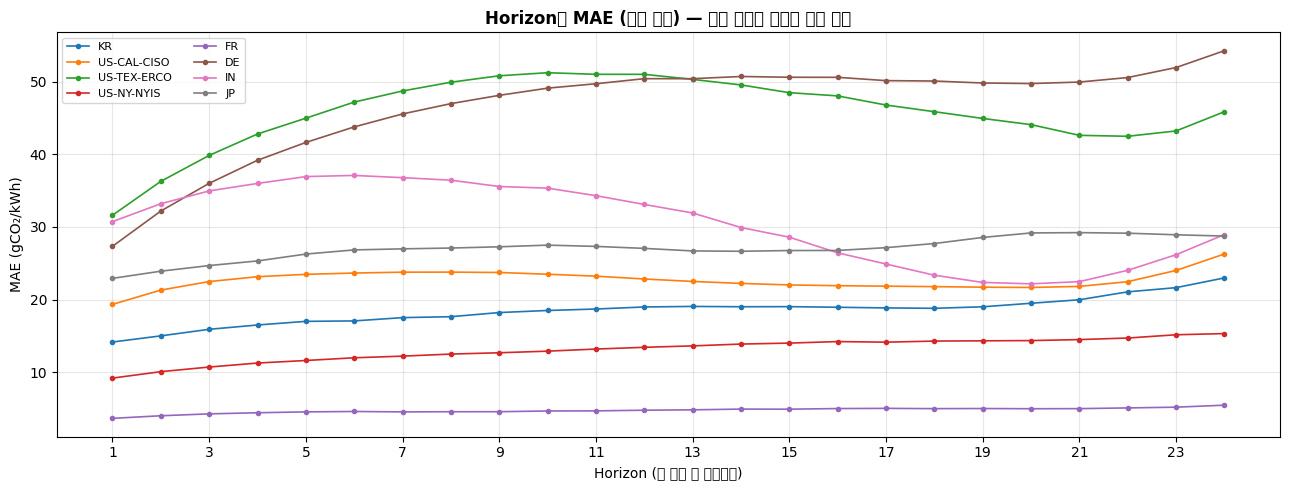


Horizon 1h vs 24h MAE 비교:
리전               horizon=1  horizon=24      증가율
--------------------------------------------------
KR                   14.17       22.99    62.3%
US-CAL-CISO          19.35       26.28    35.8%
US-TEX-ERCO          31.61       45.85    45.0%
US-NY-NYIS            9.21       15.33    66.5%
FR                    3.68        5.48    49.2%
DE                   27.34       54.24    98.4%
IN                   30.73       28.95    -5.8%
JP                   22.93       28.75    25.4%


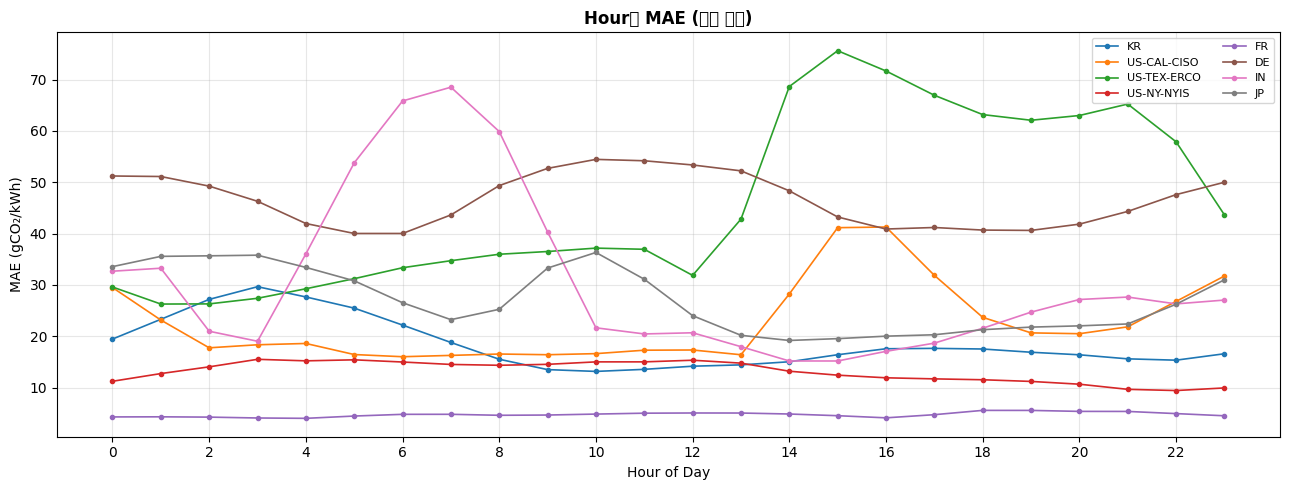

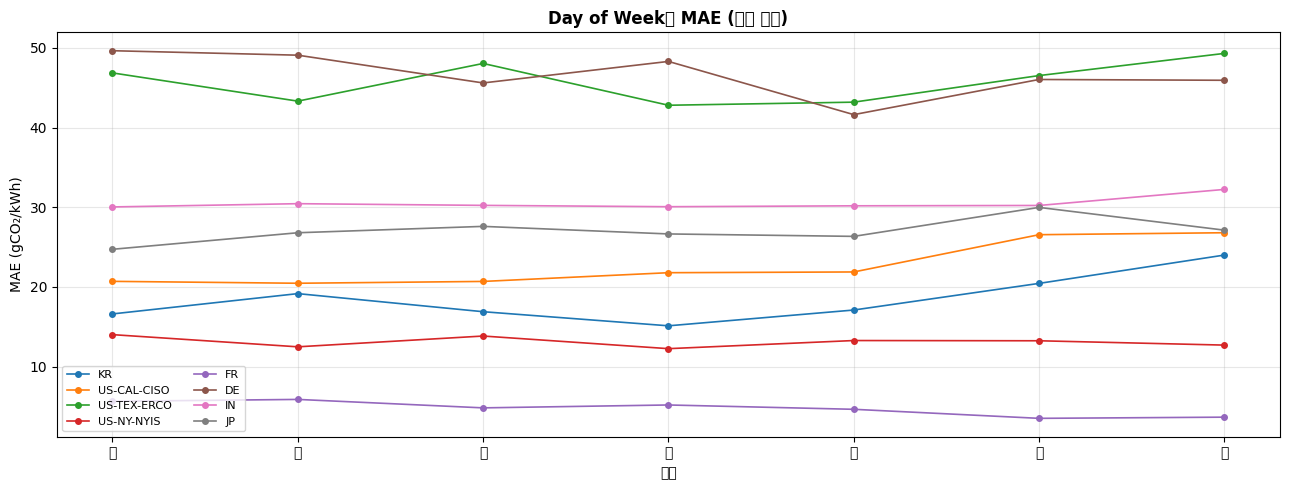

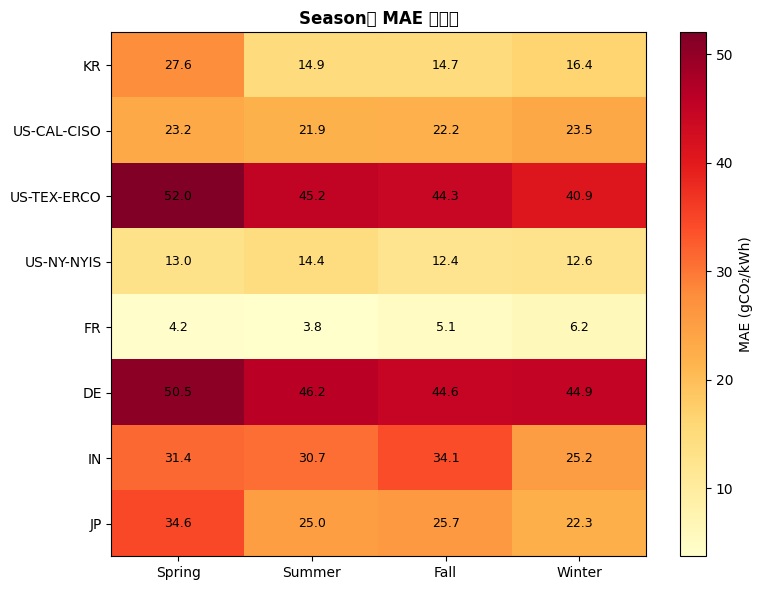

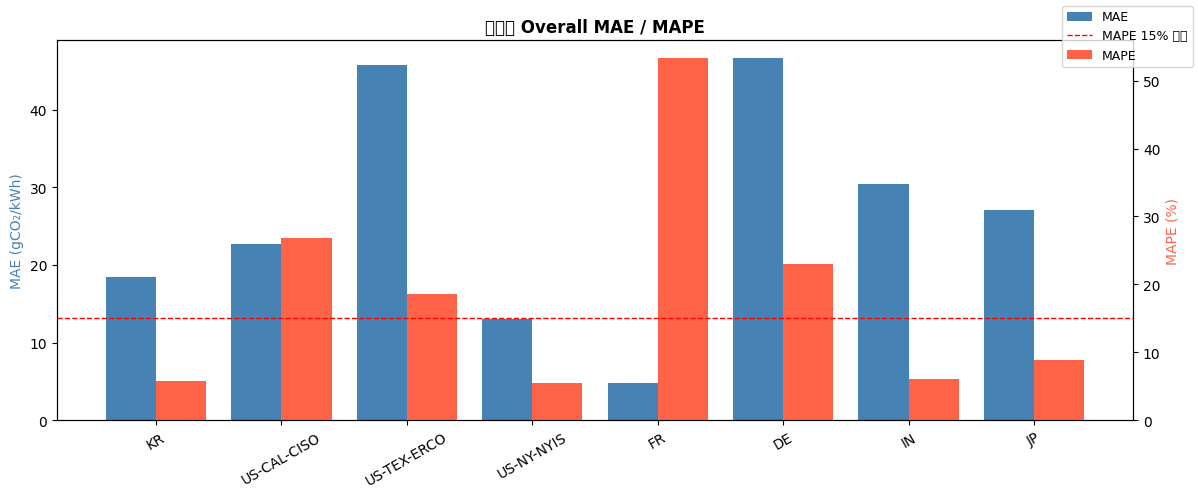

생성된 시각화:
  mae_by_horizon.png - 예측 시점(1~24h)별 오차 증가 곡선
  mae_by_hour.png    — 시간대별 예측 난이도
  mae_by_dow.png     — 요일별 예측 난이도
  mae_by_season.png  — 계절별 히트맵
  mae_by_region.png  — 리전별 MAE/MAPE 비교


In [20]:
pattern_log = {}

for region in REGIONS.keys():
    df = region_eval_dfs[region]
    pattern_log[region] = {
        'horizon': df.groupby('horizon')['abs_err'].mean().round(2).to_dict(),  # [추가]
        'hour':    df.groupby('hour')['abs_err'].mean().round(2).to_dict(),
        'dow':     df.groupby('dow')['abs_err'].mean().round(2).to_dict(),
        'season':  df.groupby('season')['abs_err'].mean().round(2).to_dict(),
    }

pattern_path = os.path.join(LOG_DIR, 'evaluation_patterns.json')
with open(pattern_path, 'w') as f:
    json.dump(pattern_log, f, indent=2, default=str)
print(f"패턴별 지표 저장 → {pattern_path}")


# (1) Horizon별 MAE (forecast horizon vs error curve)
# 1h 후 예측(horizon=1)이 24h 후 예측(horizon=24)보다 보통 더 정확함

plt.figure(figsize=(13, 5))
for region in REGIONS.keys():
    df = region_eval_dfs[region]
    horizon_mae = df.groupby('horizon')['abs_err'].mean()
    plt.plot(horizon_mae.index, horizon_mae.values, marker='o',
             markersize=3, linewidth=1.2, label=region)
plt.title('Horizon별 MAE (리전 비교) — 예측 시점이 멀수록 오차 증가',
          fontsize=12, fontweight='bold')
plt.xlabel('Horizon (몇 시간 후 예측인가)')
plt.ylabel('MAE (gCO₂/kWh)')
plt.xticks(range(1, 25, 2))
plt.legend(fontsize=8, ncol=2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(LOG_DIR, 'mae_by_horizon.png'), dpi=150, bbox_inches='tight')
plt.show()

# horizon=1 (가장 가까운 예측) vs horizon=24 (가장 먼 예측) 비교표
print("\nHorizon 1h vs 24h MAE 비교:")
print(f"{'리전':<15} {'horizon=1':>10} {'horizon=24':>11} {'증가율':>8}")
print("-"*50)
for region in REGIONS.keys():
    df = region_eval_dfs[region]
    h1  = df[df['horizon'] == 1]['abs_err'].mean()
    h24 = df[df['horizon'] == 24]['abs_err'].mean()
    increase = (h24 - h1) / h1 * 100 if h1 > 0 else float('nan')
    print(f"{region:<15} {h1:>10.2f} {h24:>11.2f} {increase:>7.1f}%")

# (2) Hour별 MAE
plt.figure(figsize=(13, 5))
for region in REGIONS.keys():
    df = region_eval_dfs[region]
    hourly = df.groupby('hour')['abs_err'].mean()
    plt.plot(hourly.index, hourly.values, marker='o',
             markersize=3, linewidth=1.2, label=region)
plt.title('Hour별 MAE (리전 비교)', fontsize=12, fontweight='bold')
plt.xlabel('Hour of Day')
plt.ylabel('MAE (gCO₂/kWh)')
plt.xticks(range(0, 24, 2))
plt.legend(fontsize=8, ncol=2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(LOG_DIR, 'mae_by_hour.png'), dpi=150, bbox_inches='tight')
plt.show()

# (3) Day of Week별 MAE
dow_labels = ['월', '화', '수', '목', '금', '토', '일']
plt.figure(figsize=(13, 5))
for region in REGIONS.keys():
    df = region_eval_dfs[region]
    dow_mae = df.groupby('dow')['abs_err'].mean()
    plt.plot(dow_mae.index, dow_mae.values, marker='o',
             markersize=4, linewidth=1.2, label=region)
plt.title('Day of Week별 MAE (리전 비교)', fontsize=12, fontweight='bold')
plt.xlabel('요일')
plt.ylabel('MAE (gCO₂/kWh)')
plt.xticks(range(7), dow_labels)
plt.legend(fontsize=8, ncol=2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(LOG_DIR, 'mae_by_dow.png'), dpi=150, bbox_inches='tight')
plt.show()

# (4) Season별 MAE — 리전 × 계절 히트맵
season_order = ['Spring', 'Summer', 'Fall', 'Winter']
heat = np.zeros((len(REGIONS), 4))
for i, region in enumerate(REGIONS.keys()):
    df = region_eval_dfs[region]
    s_mae = df.groupby('season')['abs_err'].mean()
    for j, s in enumerate(season_order):
        heat[i, j] = s_mae.get(s, np.nan)

plt.figure(figsize=(8, 6))
im = plt.imshow(heat, cmap='YlOrRd', aspect='auto')
plt.colorbar(im, label='MAE (gCO₂/kWh)')
plt.xticks(range(4), season_order)
plt.yticks(range(len(REGIONS)), list(REGIONS.keys()))
for i in range(len(REGIONS)):
    for j in range(4):
        if not np.isnan(heat[i, j]):
            plt.text(j, i, f'{heat[i, j]:.1f}',
                     ha='center', va='center', fontsize=9)
plt.title('Season별 MAE 히트맵', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(LOG_DIR, 'mae_by_season.png'), dpi=150, bbox_inches='tight')
plt.show()

# (5) 리전별 Overall MAE, MAPE
regions_list = list(REGIONS.keys())
mae_vals  = [overall_log[r]['mae']  for r in regions_list]
mape_vals = [overall_log[r]['mape'] for r in regions_list]

x = np.arange(len(regions_list))
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(x - 0.2, mae_vals, width=0.4, color='steelblue', label='MAE')
ax1.set_ylabel('MAE (gCO₂/kWh)', color='steelblue')
ax2 = ax1.twinx()
ax2.bar(x + 0.2, mape_vals, width=0.4, color='tomato', label='MAPE')
ax2.set_ylabel('MAPE (%)', color='tomato')
ax2.axhline(y=15, color='red', linestyle='--', linewidth=1, label='MAPE 15% 기준')
ax1.set_xticks(x)
ax1.set_xticklabels(regions_list, rotation=30)
plt.title('리전별 Overall MAE / MAPE', fontsize=12, fontweight='bold')
fig.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(LOG_DIR, 'mae_by_region.png'), dpi=150, bbox_inches='tight')
plt.show()

print("생성된 시각화:")
print("  mae_by_horizon.png - 예측 시점(1~24h)별 오차 증가 곡선")
print("  mae_by_hour.png    — 시간대별 예측 난이도")
print("  mae_by_dow.png     — 요일별 예측 난이도")
print("  mae_by_season.png  — 계절별 히트맵")
print("  mae_by_region.png  — 리전별 MAE/MAPE 비교")